In [1]:
import pandas as pd

# load only the columns we need (fast, saves memory)
data = pd.read_parquet(r"D:\retailpulse\retailpulse_sales_clean.parquet",
                       columns=["customer_id", "receipt_id", "date", "quantity", "total_value"])

# "today" = the day after the last sale in the data
today = data["date"].max() + pd.Timedelta(days=1)

customer = data.groupby("customer_id", observed=True).agg(
    first_purchase=("date", "min"),          # first time they bought
    last_purchase=("date", "max"),           # last time they bought
    frequency=("receipt_id", "nunique"),     # how many separate purchases (receipts)
    monetary=("total_value", "sum"),         # total money spent
    items_bought=("quantity", "sum"),
).reset_index()

customer["recency_days"]   = (today - customer["last_purchase"]).dt.days   # days since last purchase
customer["avg_order_value"] = customer["monetary"] / customer["frequency"]

print(customer.shape)
customer.describe()

(10000, 8)


,first_purchase,last_purchase,frequency,monetary,items_bought,recency_days,avg_order_value
count,10000,10000,10000.000000,1.000000e+04,10000.000000,10000.000000,10000.000000
mean,2022-01-04 22:08:24,2025-12-29 03:25:20.640000,516.786400,1.087081e+06,1868.325000,2.857400,2103.520823
min,2022-01-01 00:00:00,2025-12-01 00:00:00,255.000000,4.814559e+05,898.000000,1.000000,1638.905924
25%,2022-01-02 00:00:00,2025-12-28 00:00:00,332.000000,7.046501e+05,1206.000000,1.000000,2027.856197
50%,2022-01-03 00:00:00,2025-12-30 00:00:00,456.000000,9.515579e+05,1641.000000,2.000000,2102.022054
75%,2022-01-06 00:00:00,2025-12-31 00:00:00,680.000000,1.406493e+06,2444.000000,4.000000,2178.240507
max,2022-02-26 00:00:00,2025-12-31 00:00:00,1175.000000,2.584020e+06,4413.000000,31.000000,2542.776172
std,NaN,NaN,231.301359,4.895845e+05,838.076079,2.525253,114.382777


In [ ]:
import numpy as np

# rank first, so ties never cause errors
customer["R"] = pd.qcut(customer["recency_days"].rank(method="first"), 5, labels=[5, 4, 3, 2, 1]).astype(int)  # recent buyers get 5
customer["F"] = pd.qcut(customer["frequency"].rank(method="first"),    5, labels=[1, 2, 3, 4, 5]).astype(int)
customer["M"] = pd.qcut(customer["monetary"].rank(method="first"),     5, labels=[1, 2, 3, 4, 5]).astype(int)
customer["rfm_score"] = customer["R"] + customer["F"] + customer["M"]

conditions = [
    (customer["R"] <= 2) & (customer["F"] >= 3),   # used to buy often, gone quiet
    customer["rfm_score"] >= 12,                    # buy recently, often, and spend a lot
    customer["rfm_score"] >= 8,
]
labels = ["About to Churn", "High Value", "Regular"]
customer["segment"] = np.select(conditions, labels, default="Low Activity")

print(customer["segment"].value_counts())
customer.head()

segment
Low Activity      3414
High Value        2614
Regular           2146
About to Churn    1826
Name: count, dtype: int64


,customer_id,first_purchase,last_purchase,frequency,monetary,items_bought,recency_days,avg_order_value,R,F,M,rfm_score,segment
0,CUST00001,2022-01-06,2025-12-29,460,943800.74,1626,3,2051.740739,2,3,3,8,About to Churn
1,CUST00002,2022-01-09,2025-12-30,439,965918.81,1674,2,2200.270638,4,3,3,10,Regular
2,CUST00003,2022-01-13,2025-12-30,323,649917.08,1164,2,2012.127183,4,1,1,6,Low Activity
3,CUST00004,2022-01-07,2025-12-31,475,1028273.13,1710,1,2164.785537,5,3,4,12,High Value
4,CUST00005,2022-01-04,2025-12-29,293,598947.09,1070,3,2044.188020,2,1,1,4,Low Activity


In [ ]:
print(customer["recency_days"].describe())

for d in [7, 14, 30, 60, 90]:
    print(f"No purchase in the last {d} days:", (customer["recency_days"] > d).sum(), "customers")

count    10000.000000
mean         2.857400
std          2.525253
min          1.000000
25%          1.000000
50%          2.000000
75%          4.000000
max         31.000000
Name: recency_days, dtype: float64
No purchase in the last 7 days: 584 customers
No purchase in the last 14 days: 48 customers
No purchase in the last 30 days: 1 customers
No purchase in the last 60 days: 0 customers
No purchase in the last 90 days: 0 customers


In [ ]:
last_90 = data[data["date"] >= today - pd.Timedelta(days=90)]
prev_90 = data[(data["date"] < today - pd.Timedelta(days=90)) &
               (data["date"] >= today - pd.Timedelta(days=180))]

customer["purchases_last_90"] = customer["customer_id"].map(
    last_90.groupby("customer_id", observed=True)["receipt_id"].nunique()).fillna(0)
customer["purchases_prev_90"] = customer["customer_id"].map(
    prev_90.groupby("customer_id", observed=True)["receipt_id"].nunique()).fillna(0)

customer["activity_change"] = (customer["purchases_last_90"] - customer["purchases_prev_90"]) / customer["purchases_prev_90"]
print(customer["activity_change"].describe())
print("Customers who dropped by more than 50%:", (customer["activity_change"] < -0.5).sum())

count    10000.000000
mean         0.215967
std          0.323262
min         -0.621622
25%          0.000000
50%          0.176073
75%          0.384615
max          2.153846
Name: activity_change, dtype: float64
Customers who dropped by more than 50%: 12


In [ ]:
for cut in [-0.10, -0.20, -0.25, -0.30, -0.40]:
    print(f"dropped by more than {abs(cut)*100:.0f}%:", (customer["activity_change"] < cut).sum())
print("same or lower than before:", (customer["activity_change"] <= 0).sum())

dropped by more than 10%: 1380
dropped by more than 20%: 655
dropped by more than 25%: 416
dropped by more than 30%: 244
dropped by more than 40%: 74
same or lower than before: 2703


In [ ]:
# usual gap = days between first and last purchase, divided by number of purchases
customer["usual_gap_days"] = (customer["last_purchase"] - customer["first_purchase"]).dt.days / (customer["frequency"] - 1).clip(lower=1)

# how many times longer than usual has the customer been silent?
customer["silence_ratio"] = customer["recency_days"] / customer["usual_gap_days"]

print(customer["usual_gap_days"].describe())
print(customer["silence_ratio"].describe())
for r in [2, 3, 4, 5]:
    print(f"silent for more than {r}x their usual gap:", (customer["silence_ratio"] > r).sum())

count    10000.000000
mean         3.288398
std          1.121513
min          1.242760
25%          2.147275
50%          3.193833
75%          4.388554
max          5.708661
Name: usual_gap_days, dtype: float64
count    10000.000000
mean         0.895811
std          0.688847
min          0.185871
25%          0.440021
50%          0.691833
75%          1.177763
max          7.098739
Name: silence_ratio, dtype: float64
silent for more than 2x their usual gap: 737
silent for more than 3x their usual gap: 171
silent for more than 4x their usual gap: 41
silent for more than 5x their usual gap: 9


In [ ]:
customer["churn_risk"] = np.select(
    [
        (customer["silence_ratio"] > 2)   | (customer["activity_change"] < -0.25),   # High
        (customer["silence_ratio"] > 1.5) | (customer["activity_change"] < -0.10),   # Medium
    ],
    ["High Risk", "Medium Risk"],
    default="Low Risk",
)
print(customer["churn_risk"].value_counts())

churn_risk
Low Risk       7442
Medium Risk    1464
High Risk      1094
Name: count, dtype: int64


In [ ]:
top20 = customer["monetary"].quantile(0.80)    # spends more than 80% of customers
mid   = customer["monetary"].quantile(0.40)

customer["segment"] = np.select(
    [
        customer["churn_risk"] == "High Risk",   # first rule wins: at-risk customers are flagged
        customer["monetary"] >= top20,
        customer["monetary"] >= mid,
    ],
    ["About to Churn", "High Value", "Regular"],
    default="Low Value",
)
print(customer["segment"].value_counts())
print("Fewest purchases by any customer:", customer["frequency"].min())

segment
Regular           3648
Low Value         3460
High Value        1798
About to Churn    1094
Name: count, dtype: int64
Fewest purchases by any customer: 255


In [ ]:
top20 = customer["monetary"].quantile(0.80)    # spends more than 80% of customers
mid   = customer["monetary"].quantile(0.40)

customer["segment"] = np.select(
    [
        customer["churn_risk"] == "High Risk",   # first rule wins: at-risk customers are flagged
        customer["monetary"] >= top20,
        customer["monetary"] >= mid,
    ],
    ["About to Churn", "High Value", "Regular"],
    default="Low Value",
)
print(customer["segment"].value_counts())
print("Fewest purchases by any customer:", customer["frequency"].min())

segment
Regular           3648
Low Value         3460
High Value        1798
About to Churn    1094
Name: count, dtype: int64
Fewest purchases by any customer: 255


In [ ]:
customer.to_parquet(r"D:\retailpulse\customer_table.parquet", index=False)
customer.to_csv(r"D:\retailpulse\customer_table.csv", index=False)

In [ ]:
pip install scikit-learn

Note: you may need to restart the kernel to use updated packages.


In [ ]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

features = ["recency_days", "frequency", "monetary", "avg_order_value", "activity_change"]

# put all columns on the same scale so that big numbers (money) don't dominate
X = StandardScaler().fit_transform(customer[features])

for k in range(3, 9):
    model = KMeans(n_clusters=k, random_state=42, n_init=10).fit(X)
    score = silhouette_score(X, model.labels_)
    print(f"k={k}   inertia={model.inertia_:.0f}   silhouette={score:.3f}")

k=3   inertia=28369   silhouette=0.288
k=4   inertia=23772   silhouette=0.258
k=5   inertia=20067   silhouette=0.266
k=6   inertia=16750   silhouette=0.294
k=7   inertia=15549   silhouette=0.263
k=8   inertia=14540   silhouette=0.257


In [ ]:
k = 6      # <- change after looking at Cell 10

final = KMeans(n_clusters=k, random_state=42, n_init=10).fit(X)
customer["cluster"] = final.labels_

profile = customer.groupby("cluster").agg(
    customers=("customer_id", "count"),
    recency_days=("recency_days", "mean"),
    frequency=("frequency", "mean"),
    monetary=("monetary", "mean"),
    avg_order_value=("avg_order_value", "mean"),
    activity_change=("activity_change", "mean"),
).round(2)
profile

,customers,recency_days,frequency,monetary,avg_order_value,activity_change
cluster,,,,,,
0,2448,2.44,393.61,787713.96,2000.37,0.10
1,1020,1.53,1071.39,2254506.28,2104.20,0.19
2,2413,2.47,396.45,876814.19,2214.09,0.11
3,1328,2.33,394.56,828287.84,2099.75,0.77
4,963,8.82,366.95,768291.96,2092.79,0.08
5,1828,1.91,698.86,1470078.30,2103.71,0.19


In [ ]:
pd.crosstab(customer["cluster"], customer["segment"])

segment,About to Churn,High Value,Low Value,Regular
cluster,,,,
0,147,0,1243,1058
1,114,906,0,0
2,155,2,1098,1158
3,8,10,753,557
4,549,0,366,48
5,121,880,0,827


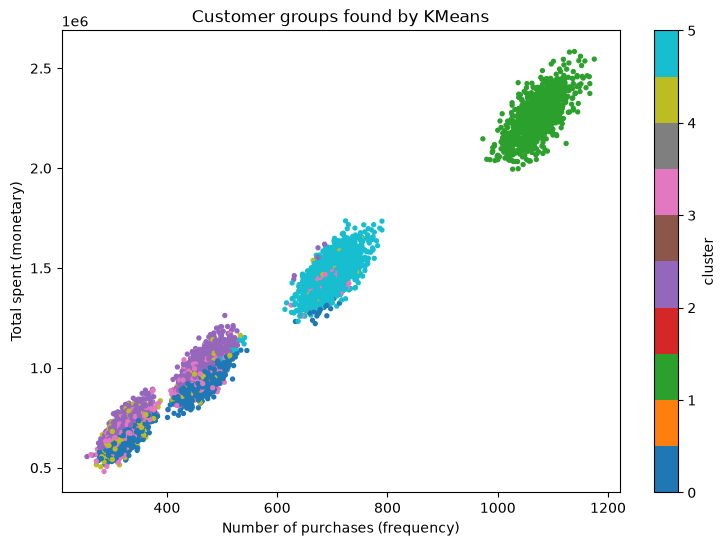

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 6))
plt.scatter(customer["frequency"], customer["monetary"], c=customer["cluster"], cmap="tab10", s=8)
plt.xlabel("Number of purchases (frequency)")
plt.ylabel("Total spent (monetary)")
plt.title("Customer groups found by KMeans")
plt.colorbar(label="cluster")
plt.show()

In [ ]:
names = {
    0: "name here",
    1: "name here",
    2: "name here",
    3: "name here",
    4: "name here",
    5: "name here",
}
customer["cluster_name"] = customer["cluster"].map(names)

customer.to_parquet(r"D:\retailpulse\customer_table.parquet", index=False)
customer.to_csv(r"D:\retailpulse\customer_table.csv", index=False)
customer["cluster_name"].value_counts()

cluster_name
name here    10000
Name: count, dtype: int64

In [ ]:
profile = customer.groupby("cluster").agg(
    customers=("customer_id", "count"),
    recency_days=("recency_days", "mean"),
    frequency=("frequency", "mean"),
    monetary=("monetary", "mean"),
    avg_order_value=("avg_order_value", "mean"),
    activity_change=("activity_change", "mean"),
    churn_high_share=("churn_risk", lambda s: (s == "High Risk").mean()),
).round(2)
profile

,customers,recency_days,frequency,monetary,avg_order_value,activity_change,churn_high_share
cluster,,,,,,,
0,2448,2.44,393.61,787713.96,2000.37,0.10,0.06
1,1020,1.53,1071.39,2254506.28,2104.20,0.19,0.11
2,2413,2.47,396.45,876814.19,2214.09,0.11,0.06
3,1328,2.33,394.56,828287.84,2099.75,0.77,0.01
4,963,8.82,366.95,768291.96,2092.79,0.08,0.57
5,1828,1.91,698.86,1470078.30,2103.71,0.19,0.07


In [ ]:
names = {
    0: "Steady Regulars",
    1: "VIP Power Shoppers",
    2: "Big-Basket Regulars",
    3: "Rising Customers",
    4: "Slowing Down (Win-back)",
    5: "Loyal Frequent Shoppers",
}
customer["cluster_name"] = customer["cluster"].map(names)

customer.to_parquet(r"D:\retailpulse\customer_table.parquet", index=False)
customer.to_csv(r"D:\retailpulse\customer_table.csv", index=False)
customer["cluster_name"].value_counts()

cluster_name
Steady Regulars            2448
Big-Basket Regulars        2413
Loyal Frequent Shoppers    1828
Rising Customers           1328
VIP Power Shoppers         1020
Slowing Down (Win-back)     963
Name: count, dtype: int64